In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torchvision import datasets,transforms
from torch.utils.data import DataLoader,Dataset
import pickle
class CustomCNN(nn.Module):
  def __init__(self,in_channels,num_classes,image_size):
    super().__init__()
    self.conv1=nn.Conv2d(in_channels,32,kernel_size=3,padding=1)#(입력 채널, 출력 채널, 필터 크기, 패딩)
    self.conv2=nn.Conv2d(32,64,kernel_size=3,padding=1)
    self.maxpool1=nn.MaxPool2d(2,2)
    self.maxpool2=nn.MaxPool2d(2,2)
    self.linear1=nn.Linear(64 * (image_size // 4) * (image_size // 4),128)
    self.linear2=nn.Linear(128,num_classes)
  def forward(self,x):
    x=self.conv1(x)
    x=F.relu(x)
    x=self.maxpool1(x)
    x=self.conv2(x)
    x=F.relu(x)
    x=self.maxpool2(x)
    x=torch.flatten(x, start_dim=1)
    x=self.linear1(x)
    x=F.relu(x)
    x=self.linear2(x)
    return x
class CustomDataset:
  def __init__(self,root_dir,label_map,transform):
    self.root_dir=root_dir
    self.label_map=label_map
    self.transform=transform
    self.samples=[]
    for class_name, label in label_map.items():
      class_dir=self.root_dir/class_name
      for img_path in class_dir.glob('*.jpg'):
        self.samples.append((img_path,label))
  def __len__(self):
    return len(self.samples)
  def __getitem__(self,idx):
    img_path,label=self.samples[idx]
    image=Image.open(img_path).convert('RGB')

    if self.transform is not None:
      image=self.transform(image)
    return image, torch.tensor(label,dtype=torch.long)


class CustomCIFAR10Dataset(Dataset):

  def __init__(self, images, labels, transform=None):
    self.images = images.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    self.labels = labels
    self.transform = transform

  def __len__(self):
    return len(self.labels)

  def __getitem__(self, idx):
    image = self.images[idx]
    label = self.labels[idx]

    if self.transform:
      image = self.transform(image)

    return image, torch.tensor(label, dtype=torch.long)


def load_cifar_batch(file_path):
  with open(file_path, 'rb') as f:
    batch = pickle.load(f, encoding='bytes')
  return batch[b'data'], batch[b'labels']


def unnormalize(tensor_img):
  # CIFAR-10 Normalize 역변환: (img * std) + mean
  mean = np.array([0.4914, 0.4822, 0.4465]).reshape(3, 1, 1)
  std = np.array([0.2023, 0.1994, 0.2010]).reshape(3, 1, 1)

  npimg = tensor_img.cpu().numpy()
  npimg = npimg * std + mean
  npimg = np.clip(npimg, 0.0, 1.0)
  return np.transpose(npimg, (1, 2, 0))

In [ ]:
transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.1307,),(0.3081,))])

train_dataset=datasets.MNIST(root='./data',train=True,download=True,transform=transform)
test_dataset=datasets.MNIST(root='./data',train=False,download=True,transform=transform)

train_loader=DataLoader(train_dataset,batch_size=64,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=1000,shuffle=False)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model=CustomCNN(in_channels=1,num_classes=10,image_size=28).to(device)
criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=0.001)
epochs=5
for epoch in range(1,epochs+1):
  model.train()
  train_loss=0.0
  correct_train=0
  total_train=0

  for images, labels in train_loader:

    images=images.to(device)
    labels=labels.to(device)
    optimizer.zero_grad()
    outputs=model(images)
    loss=criterion(outputs,labels)
    loss.backward()
    optimizer.step()

    train_loss+=loss.item()*images.size(0)
    _,predicted=torch.max(outputs,1)
    total_train+=labels.size(0)
    correct_train+=(predicted==labels).sum().item()
  epoch_train_loss=train_loss/total_train
  epoch_train_acc=correct_train/total_train

  model.eval()
  test_loss=0.0
  correct_test=0
  total_test=0

  with torch.no_grad():
    for images, labels in test_loader:
      images=images.to(device)
      labels=labels.to(device)

      outputs=model(images)
      loss=criterion(outputs,labels)

      test_loss+=loss.item()*images.size(0)
      _,predicted=torch.max(outputs,1)
      total_test+=labels.size(0)
      correct_test+=(predicted==labels).sum().item()

  epoch_test_loss=test_loss/total_test
  epoch_test_acc=correct_test/total_test

  print(epoch)
  print(f"{epoch_train_loss:.4f},{ epoch_train_acc:.4f}")
  print(f"{epoch_test_loss:.4f},{ epoch_test_acc:.4f}")
torch.save(model.state_dict(), 'custom_cnn_mnist.pth')

100%|██████████| 9.91M/9.91M [00:00<00:00, 54.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.70MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 13.9MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.10MB/s]


KeyboardInterrupt: 

In [ ]:
def predict_image(image_path, model_path):
  device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


  transform = transforms.Compose([
      transforms.Grayscale(num_output_channels=1),
      transforms.Resize((28, 28)),
      transforms.ToTensor(),
      transforms.Normalize((0.1307,), (0.3081,)),
  ])

  image = Image.open(image_path)
  input_tensor = transform(image)

  input_tensor = input_tensor.unsqueeze(0).to(device)


  model = CustomCNN(in_channels=1, num_classes=10, image_size=28).to(device)
  model.load_state_dict(torch.load(model_path, map_location=device))
  model.eval()

  with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = F.softmax(outputs, dim=1)
    confidence, predicted_class = torch.max(
        probabilities, 1
    )

  predicted = predicted_class.item()
  prob_percent = confidence.item() * 100

  print(f'예측된 숫자: {predicted}')
  print(f'확신도(Probability): {prob_percent:.2f}%')

  return predicted
predict_image('/content/제목 없음.png','/content/custom_cnn_mnist.pth')

In [ ]:
!tar -zxvf /content/cifar-10-python.tar.gz -C /content/

cifar-10-batches-py/
cifar-10-batches-py/data_batch_4
cifar-10-batches-py/readme.html
cifar-10-batches-py/test_batch
cifar-10-batches-py/data_batch_3
cifar-10-batches-py/batches.meta
cifar-10-batches-py/data_batch_2
cifar-10-batches-py/data_batch_5
cifar-10-batches-py/data_batch_1


In [ ]:
!pip install wandb

In [ ]:
!wandb login

wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.
wandb: Paste your API key and hit enter: 
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: tnsgh2120 (tnsgh2120-kku-ac-kr) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## CONFIG

In [4]:
import wandb
wandb.init(
    project="CNN-CIFAR10",
    config={
        "architecture": "CNN",
        "dataset": "CIFAR-10",
        "learning_rate": 0.001,
        "batch_size": 64,
        "epochs": 35,
        "optimizer": "SGD_Momentum",
        "momentum": 0.9,
        "weight_decay": 0.0005,
    },
)
config = wandb.config

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 3


wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch import optim
from torchvision import transforms

# ---------------------------------------------------------
# 데이터셋 로드
# ---------------------------------------------------------
X_train_list, y_train_list = [], []
for i in range(1, 6):
  img, lbl = load_cifar_batch(f'/content/cifar-10-batches-py/data_batch_{i}')
  X_train_list.append(img)
  y_train_list.extend(lbl)

X_train = np.concatenate(X_train_list, axis=0)
y_train = np.array(y_train_list)

# [수정] 테스트 세트는 test_batch 파일에서 불러옴
X_test, y_test = load_cifar_batch('/content/cifar-10-batches-py/test_batch')
y_test = np.array(y_test)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

train_dataset = CustomCIFAR10Dataset(X_train, y_train, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=config["batch_size"], shuffle=True)

test_dataset = CustomCIFAR10Dataset(X_test, y_test, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = CustomCNN(in_channels=3, num_classes=10, image_size=32).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(
    model.parameters(),
    lr=config.learning_rate,
    momentum=config.momentum,
    weight_decay=config.weight_decay,
)

wandb.watch(model, log='all', log_freq=100)
epochs = 35
classes = (
    'plane',
    'car',
    'bird',
    'cat',
    'deer',
    'dog',
    'frog',
    'horse',
    'ship',
    'truck',
)
best_test_loss = float('inf')
# ---------------------------------------------------------
# 학습 및 검증 루프
# ---------------------------------------------------------
for epoch in range(1, epochs + 1):
  model.train()
  train_loss = 0.0
  correct_train = 0
  total_train = 0

  for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)
    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    train_loss += loss.item() * images.size(0)
    _, predicted = torch.max(outputs, 1)
    total_train += labels.size(0)
    correct_train += (predicted == labels).sum().item()

  epoch_train_loss = train_loss / total_train
  epoch_train_acc = 100.0 * correct_train / total_train

  # 검증 평가 및 전체 테스트 데이터 샘플 수집
  model.eval()
  test_loss = 0.0
  correct_test = 0
  total_test = 0

  all_correct_images, all_correct_labels, all_correct_preds = [], [], []
  all_wrong_images, all_wrong_labels, all_wrong_preds = [], [], []

  with torch.no_grad():
    for images, labels in test_loader:
      images = images.to(device)
      labels = labels.to(device)

      outputs = model(images)
      loss = criterion(outputs, labels)

      test_loss += loss.item() * images.size(0)
      _, predicted = torch.max(outputs, 1)

      total_test += labels.size(0)
      correct_test += (predicted == labels).sum().item()

      # 정답/오답 마스크 생성
      correct_mask = predicted == labels
      incorrect_mask = predicted != labels

      # CPU로 이동하여 전체 데이터 리스트에 누적 수집
      if correct_mask.sum() > 0:
        all_correct_images.append(images[correct_mask].cpu())
        all_correct_labels.append(labels[correct_mask].cpu())
        all_correct_preds.append(predicted[correct_mask].cpu())

      if incorrect_mask.sum() > 0:
        all_wrong_images.append(images[incorrect_mask].cpu())
        all_wrong_labels.append(labels[incorrect_mask].cpu())
        all_wrong_preds.append(predicted[incorrect_mask].cpu())

  epoch_test_loss = test_loss / total_test
  epoch_test_acc = 100.0 * correct_test / total_test
  epoch_test_error = 100.0 - epoch_test_acc

  # ---------------------------------------------------------
  # 전체 데이터 기준 정답 6개 / 오답 6개 시각화
  # ---------------------------------------------------------
  correct_imgs_cat = (
      torch.cat(all_correct_images, dim=0) if all_correct_images else []
  )
  correct_lbls_cat = (
      torch.cat(all_correct_labels, dim=0) if all_correct_labels else []
  )
  correct_preds_cat = (
      torch.cat(all_correct_preds, dim=0) if all_correct_preds else []
  )

  wrong_imgs_cat = torch.cat(all_wrong_images, dim=0) if all_wrong_images else []
  wrong_lbls_cat = torch.cat(all_wrong_labels, dim=0) if all_wrong_labels else []
  wrong_preds_cat = torch.cat(all_wrong_preds, dim=0) if all_wrong_preds else []

  fig = plt.figure(figsize=(14, 8))
  fig.suptitle(
      f'Epoch {epoch} Results (Total Test Acc: {epoch_test_acc:.2f}%)',
      fontsize=14,
  )

  # 상단 6개: 정답 이미지 출력 (Green)
  # num_correct_show = min(6, len(correct_imgs_cat))
  # for idx in range(num_correct_show):
  #   ax = fig.add_subplot(3, 4, idx + 1, xticks=[], yticks=[])
  #   img_rgb = unnormalize(correct_imgs_cat[idx])
  #   plt.imshow(img_rgb)

  #   gt = classes[correct_lbls_cat[idx]]
  #   pred = classes[correct_preds_cat[idx]]
  #   ax.set_title(f'Pred: {pred}\n(GT: {gt})', color='green')

  # # 하단 6개: 오답 이미지 출력 (Red)
  # num_wrong_show = min(6, len(wrong_imgs_cat))
  # for idx in range(num_wrong_show):
  #   ax = fig.add_subplot(3, 4, idx + 7, xticks=[], yticks=[])
  #   img_rgb = unnormalize(wrong_imgs_cat[idx])
  #   plt.imshow(img_rgb)

  #   gt = classes[wrong_lbls_cat[idx]]
  #   pred = classes[wrong_preds_cat[idx]]
  #   ax.set_title(f'Pred: {pred}\n(GT: {gt})', color='red')
  if epoch_test_loss < best_test_loss:
    best_test_loss = epoch_test_loss
    torch.save(model.state_dict(), 'custom_cnn_cifar10.pth')
    print(f'--> Epoch {epoch}: Best model saved!')
  plt.tight_layout()
  plt.show()

  print(f'Epoch {epoch}/{config.epochs}')
  print(f'Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%')
  print(
      f'Test Loss: {epoch_test_loss:.4f} | Test Acc: {epoch_test_acc:.2f}% |'
      f' Test Error: {epoch_test_error:.2f}%\n'
  )

  wandb.log({
      'epoch': epoch,
      'train_loss': epoch_train_loss,
      'train_accuracy': epoch_train_acc,
      'test_loss': epoch_test_loss,
      'test_error_rate': epoch_test_error,
      'test_accuracy': epoch_test_acc,
      'learning_rate': config.learning_rate,
  })

wandb.finish()

--- CIFAR-10 Training Set Channel Means ---
Red Channel Mean:   0.4914
Green Channel Mean: 0.4822
Blue Channel Mean:  0.4465


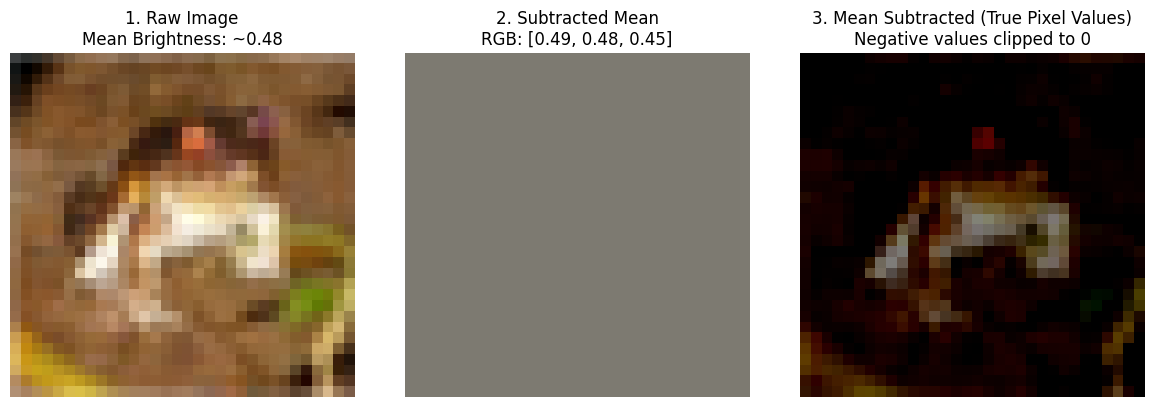

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# 1. /content 경로에 이미 존재하는 CIFAR-10 데이터셋 로드
transform_raw = transforms.Compose([
    transforms.ToTensor()
])

trainset_raw = torchvision.datasets.CIFAR10(
    root='/content', train=True, download=False, transform=transform_raw
)
trainloader_raw = torch.utils.data.DataLoader(
    trainset_raw, batch_size=50000, shuffle=False
)

# 2. 전체 50,000장 훈련 데이터의 RGB 채널별 평균(Mean) 계산
data_iter = iter(trainloader_raw)
images, labels = next(data_iter)  # Shape: (50000, 3, 32, 32)

mean_r = images[:, 0, :, :].mean().item()
mean_g = images[:, 1, :, :].mean().item()
mean_b = images[:, 2, :, :].mean().item()

print(f"--- CIFAR-10 Training Set Channel Means ---")
print(f"Red Channel Mean:   {mean_r:.4f}")
print(f"Green Channel Mean: {mean_g:.4f}")
print(f"Blue Channel Mean:  {mean_b:.4f}")

# 3. 평균 감산(Mean Subtraction) 전처리 적용
transform_subtracted = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[mean_r, mean_g, mean_b], std=[1.0, 1.0, 1.0])
])

trainset_subtracted = torchvision.datasets.CIFAR10(
    root='/content', train=True, download=False, transform=transform_subtracted
)

# 4. 진짜 밝기 변화 시각화 (Offset 없이 실제 픽셀값 기반 출력)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# (1) 원본 이미지 (Raw)
axes[0].imshow(raw_img)
axes[0].set_title(f"1. Raw Image\nMean Brightness: ~0.48")
axes[0].axis('off')

# (2) 빼는 대상 (Dataset Mean 단색)
axes[1].imshow(mean_img)
axes[1].set_title(f"2. Subtracted Mean\nRGB: [{mean_r:.2f}, {mean_g:.2f}, {mean_b:.2f}]")
axes[1].axis('off')

# (3) 진짜 평균이 차감된 이미지 (0 이하 음수 픽셀은 검은색 처리)
# 평균값 이하였던 어두운 영역들은 모두 0(Black)이 되어 밝기 차이가 뚜렷해짐
sub_img_true = np.clip(sub_img, 0, 1)
axes[2].imshow(sub_img_true)
axes[2].set_title(f"3. Mean Subtracted (True Pixel Values)\nNegative values clipped to 0")
axes[2].axis('off')

plt.tight_layout()
plt.show()

## Mean Subtraction 결과 히스토그램

In [8]:
!tar -zxvf /content/cifar-10-python.tar.gz -C /content

cifar-10-batches-py/
cifar-10-batches-py/data_batch_4
cifar-10-batches-py/readme.html
cifar-10-batches-py/test_batch
cifar-10-batches-py/data_batch_3
cifar-10-batches-py/batches.meta
cifar-10-batches-py/data_batch_2
cifar-10-batches-py/data_batch_5
cifar-10-batches-py/data_batch_1


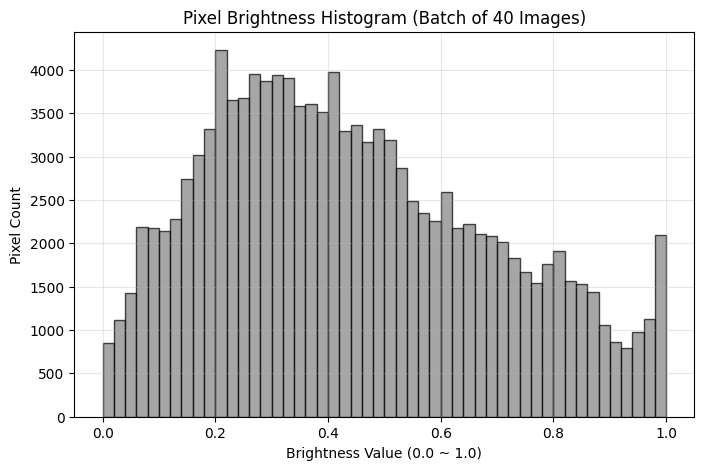

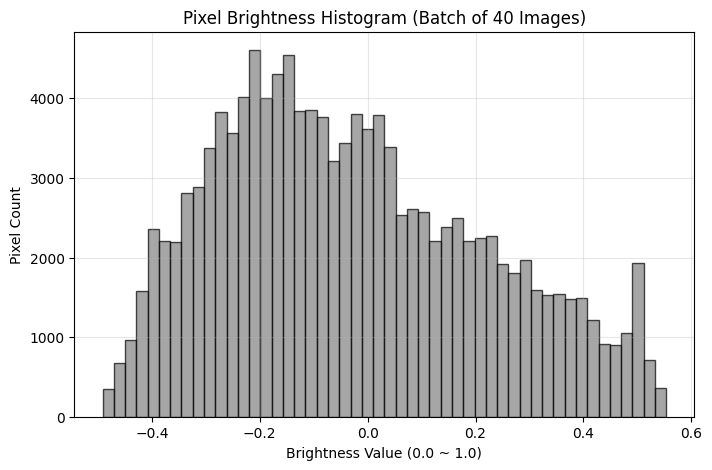

In [ ]:
import torchvision
import torchvision.transforms as transforms
import torch
import matplotlib.pyplot as plt
import numpy as np
transform=transforms.Compose([transforms.ToTensor()])
cifar10_mean = (0.4914, 0.4822, 0.4465)
cifar10_std = (1.0, 1.0, 1.0)
transform_mean_sub = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=cifar10_mean, std=cifar10_std)
])
dataset=torchvision.datasets.CIFAR10(root='/content',train=True,download=False,transform=transform)
dataset_mean_sub = torchvision.datasets.CIFAR10(
    root='/content', train=True, download=False, transform=transform_mean_sub
)
dataloader=torch.utils.data.DataLoader(dataset,batch_size=40,shuffle=False)
dataloader_mean_sub=torch.utils.data.DataLoader(dataset_mean_sub,batch_size=40,shuffle=False)

images,labels=next(iter(dataloader))
images_mean_sub,labels_mean_sub=next(iter(dataloader_mean_sub))


plt.figure(figsize=(8, 5))
plt.hist(images.ravel(), bins=50, color='gray', alpha=0.7, edgecolor='black')
plt.title('Pixel Brightness Histogram (Batch of 40 Images)')
plt.xlabel('Brightness Value (0.0 ~ 1.0)')
plt.ylabel('Pixel Count')
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(images_mean_sub.ravel(), bins=50, color='gray', alpha=0.7, edgecolor='black')
plt.title('Pixel Brightness Histogram (Batch of 40 Images)')
plt.xlabel('Brightness Value (0.0 ~ 1.0)')
plt.ylabel('Pixel Count')
plt.grid(True, alpha=0.3)
plt.show()


In [9]:
!pip install grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=b9430754fec1fd14433320f09a26a095952660a7d81c91cbc401c80f87c97cf5
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [grad-cam]


## 히트맵

=== [모델 검증 결과] ===
Test Loss    : 0.8446
Test Accuracy: 71.19%



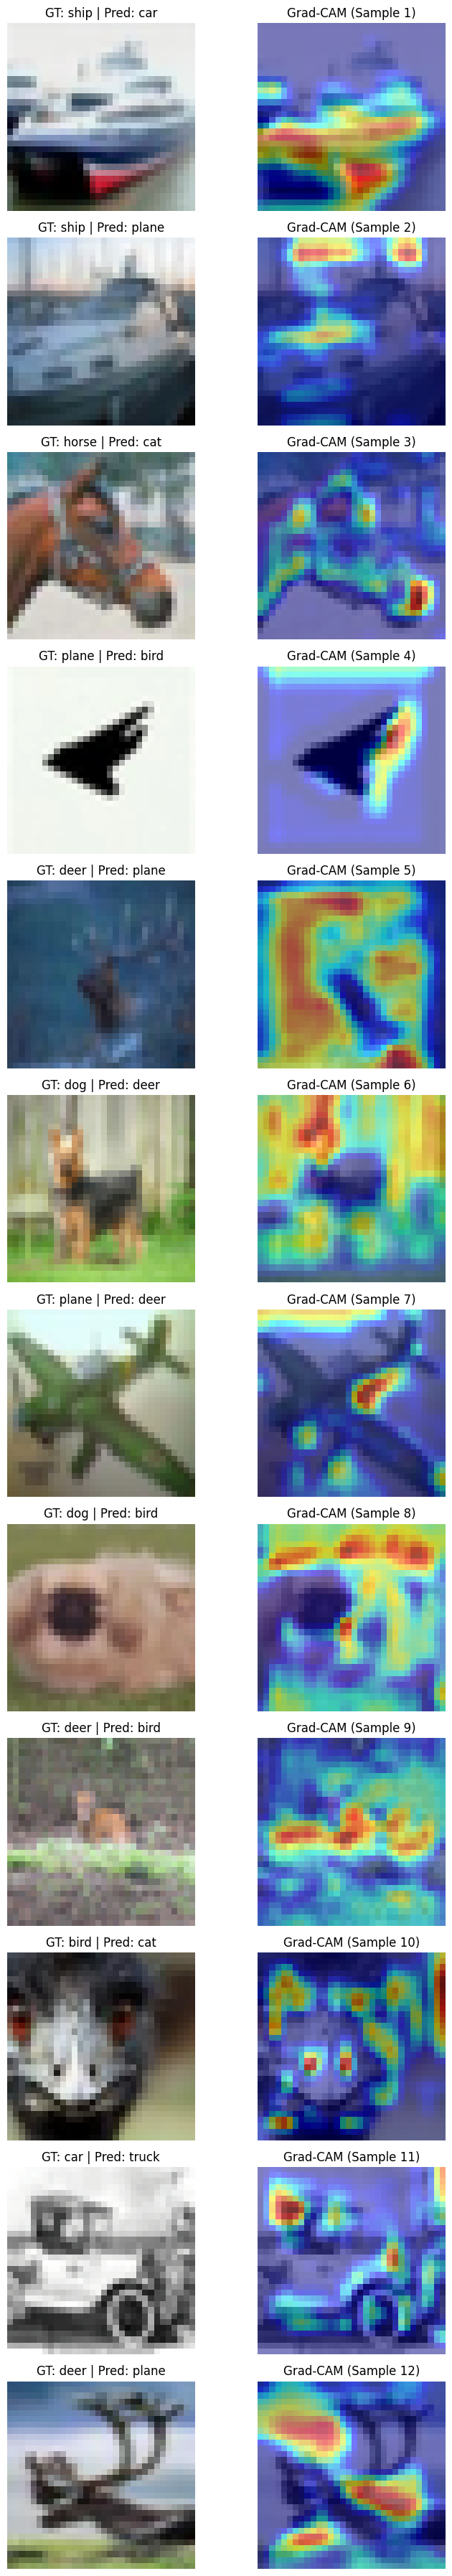

In [13]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import torch.nn as nn
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model=CustomCNN(in_channels=3,num_classes=10,image_size=32).to(device)
model_path='/content/custom_cnn_cifar10.pth'
state_dict=torch.load(model_path,map_location=device)
model.load_state_dict(state_dict)
model.eval()
X_test, y_test = load_cifar_batch('/content/cifar-10-batches-py/test_batch')

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

test_dataset = CustomCIFAR10Dataset(X_test, y_test, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)

criterion = nn.CrossEntropyLoss()

classes = (
    'plane',
    'car',
    'bird',
    'cat',
    'deer',
    'dog',
    'frog',
    'horse',
    'ship',
    'truck',
)

model.eval()
test_loss = 0.0
correct = 0
total = 0

incorrect_samples = []  # 정성평가(Grad-CAM)용 오답 데이터 저장 리스트

with torch.no_grad():
  for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)

    outputs = model(images)
    loss = criterion(outputs, labels)

    test_loss += loss.item() * images.size(0)
    _, predicted = torch.max(outputs, 1)

    total += labels.size(0)
    correct += (predicted == labels).sum().item()

    # 오답 샘플 수집 (Grad-CAM 시각화용)
    wrong_idx = predicted != labels
    for img, gt, pred in zip(
        images[wrong_idx], labels[wrong_idx], predicted[wrong_idx]
    ):
      if len(incorrect_samples) < 12:  # 4개 샘플만 수집
        incorrect_samples.append(
            (img.cpu(), gt.item(), pred.item())
        )

# 전체 성능 출력
avg_loss = test_loss / total
accuracy = 100.0 * correct / total
print(f'=== [모델 검증 결과] ===')
print(f'Test Loss    : {avg_loss:.4f}')
print(f'Test Accuracy: {accuracy:.2f}%\n')

# -------------------------------------------------------------------
# 2. Grad-CAM 히트맵 정성평가 (수집된 오답 샘플 시각화)
# -------------------------------------------------------------------
# Grad-CAM은 역전파 기울기(Gradient)가 필요하므로 no_grad 바깥에서 실행합니다.
target_layers = [model.conv2]
cam = GradCAM(model=model, target_layers=target_layers)

fig, axes = plt.subplots(len(incorrect_samples), 2, figsize=(8, 3 * len(incorrect_samples)))

# Mean Subtraction 및 Normalize 복원(Un-normalize)용 매개변수
mean = np.array([0.4914, 0.4822, 0.4465]).reshape(3, 1, 1)
std = np.array([0.2023, 0.1994, 0.2010]).reshape(3, 1, 1)

for idx, (img_tensor, gt_label, pred_label) in enumerate(incorrect_samples):
  # Grad-CAM 입력용 배치 차원 추가 [1, 3, 32, 32]
  input_tensor = img_tensor.unsqueeze(0).to(device)

  # 히트맵 계산
  grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0]

  # 시각화용 원본 이미지 복원 ([0.0, 1.0] 범위로 역스케일링)
  rgb_img = img_tensor.numpy() * std + mean
  rgb_img = np.transpose(rgb_img, (1, 2, 0))
  rgb_img = np.clip(rgb_img, 0.0, 1.0)

  # 히트맵 합성
  visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

  # subplot 출력
  ax_orig = axes[idx, 0] if len(incorrect_samples) > 1 else axes[0]
  ax_cam = axes[idx, 1] if len(incorrect_samples) > 1 else axes[1]

  ax_orig.imshow(rgb_img)
  ax_orig.set_title(f'GT: {classes[gt_label]} | Pred: {classes[pred_label]}')
  ax_orig.axis('off')

  ax_cam.imshow(visualization)
  ax_cam.set_title(f'Grad-CAM (Sample {idx+1})')
  ax_cam.axis('off')

plt.tight_layout()
plt.show()
